# Install & Import Liberaries

In [ ]:
%%capture
!pip install gym==0.26.2
!pip install pyglet==2.0.10
!pip install pygame==2.5.2
!pip install numpy==1.26.4
!pip install PyQt5 opencv-python
!pip install stable-baselines3
!pip install "stable-baselines3[extra]"
!pip install moviepy

In [ ]:
import gym
import time
import matplotlib.pyplot as plt
from IPython import display
import numpy as np
import torch
from torch import nn
import torch.nn.functional as F
from torch import optim
from torch.distributions import Categorical
from torchvision import transforms
import torchvision
from PIL import Image
from IPython.display import clear_output

# RL helpers

In [ ]:
def show_img_obs(frame, rm_pre=False):
    if rm_pre:
        display.clear_output(wait=True)

    if isinstance(frame, torch.Tensor):
        frame = frame.squeeze(0).permute(1, 2, 0).cpu().numpy()

    plt.figure(figsize=(10, 7))
    plt.imshow(frame)
    plt.axis('off')
    display.display(plt.gcf())
    plt.close()

def get_img_obs(env):
    frame = env.render()
    if frame.dtype != np.float32:
        frame = frame.astype(np.float32)
    frame /= 255.0
    frame = np.transpose(frame, (2, 0, 1))
    frame = torch.from_numpy(frame)

    return frame


def live_plot(metrics):
    clear_output(wait=True)
    fig, axes = plt.subplots(1, 4, figsize=(20, 6))

    # Epoch indices for plotting (starting from 1)
    epochs = range(1, len(metrics["train_avg_rewards"]) + 1)

    # Plot Average Rewards (Train & Eval)
    axes[0].plot(epochs, metrics["train_avg_rewards"], '-o', label="Train Avg Rewards")
    axes[0].plot(epochs, metrics["eval_avg_rewards"], '-o', color='orange', label="Eval Avg Rewards")
    axes[0].set_title("Average Rewards")
    axes[0].set_xlabel("Epoch")
    axes[0].set_ylabel("Average Reward")
    axes[0].legend()
    axes[0].grid(True)

    # Plot std Rewards (Train & Eval)
    axes[1].plot(epochs, metrics["train_std_rewards"], '-o', label="Train Std Rewards")
    axes[1].plot(epochs, metrics["eval_std_rewards"], '-o', color='orange', label="Eval Std Rewards")
    axes[1].set_title("Std Rewards")
    axes[1].set_xlabel("Epoch")
    axes[1].set_ylabel("Std Reward")
    axes[1].legend()
    axes[1].grid(True)

    # Plot Average Episode Lengths (Train & Eval)
    axes[2].plot(epochs, metrics["train_avg_epi_lens"], '-o', label="Train Avg Episode Length")
    axes[2].plot(epochs, metrics["eval_avg_epi_len"], '-o', color='orange', label="Eval Avg Episode Length")
    axes[2].set_title("Average Episode Length")
    axes[2].set_xlabel("Epoch")
    axes[2].set_ylabel("Episode Length")
    axes[2].legend()
    axes[2].grid(True)

    # Plot Accuracy (Train & Eval)
    axes[3].plot(epochs, metrics["train_acc"], '-o', label="Train Accuracy")
    axes[3].plot(epochs, metrics["eval_acc"], '-o', color='orange', label="Eval Accuracy")
    axes[3].set_title("Accuracy")
    axes[3].set_xlabel("Epoch")
    axes[3].set_ylabel("Accuracy (%)")
    axes[3].legend()
    axes[3].grid(True)

    plt.tight_layout()
    plt.show()

def evaluate_fc_policy(agent, env, n_eval_episode, threshold):
    agent.eval()
    total_rewards = []
    epi_lengths = []
    n_successes = 0

    for _ in range(n_eval_episode):
        obs, _ = env.reset()
        done = False
        total_reward = 0
        epi_len = 0
        while not done:
            with torch.no_grad():
                action_probs = agent(torch.from_numpy(obs).float().unsqueeze(0))
            action = torch.argmax(action_probs, dim=1).item()

            obs, reward, done, truncated, _ = env.step(action)
            total_reward += reward
            epi_len += 1

            if truncated:
                done = True

        total_rewards.append(total_reward)
        epi_lengths.append(epi_len)
        if total_reward >= threshold:
            n_successes += 1

    agent.train()

    eval_acc = (n_successes / n_eval_episode) * 100
    eval_avg_rewards = np.mean(total_rewards)
    eval_std_rewards = np.std(total_rewards)
    eval_avg_epi_len = np.mean(epi_lengths)

    return {
        "eval_acc": eval_acc,
        "eval_avg_rewards": eval_avg_rewards,
        "eval_std_rewards": eval_std_rewards,
        "eval_avg_epi_len": eval_avg_epi_len
    }

# Testing

### Test Env to understand it

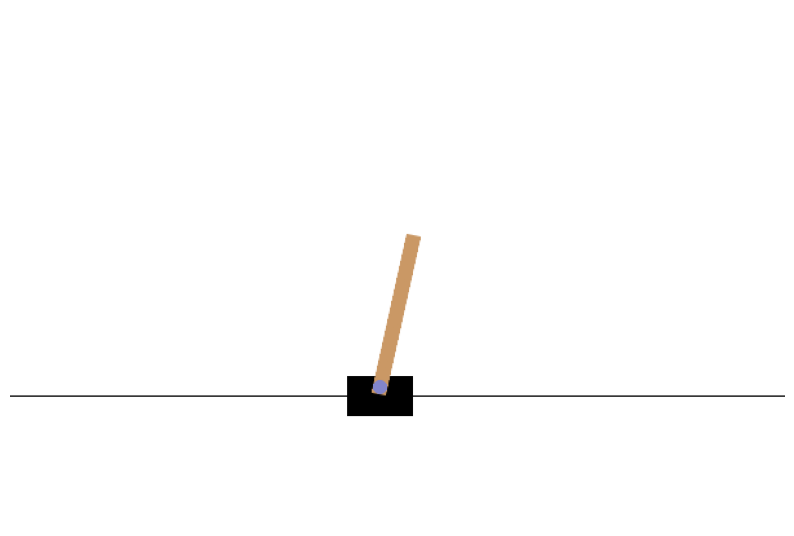

In [ ]:
# create env
env = gym.make("CartPole-v1", render_mode="rgb_array")

# action space
action_space = env.action_space
possible_actions = list(range(action_space.n))

# reward range
reward_range = env.reward_range

# infos
print(f"🚀 Environment Information:")
print(f"🎮 Possible Actions: {possible_actions}")
print(f"🏆 Reward Range: {reward_range}")

# reset env and get init obs
obs = env.reset()

# transform
im_size = 128
b_size = 32

# Run a certain number of episodes
for epi_idx in range(1):

    # one episode untill while loop is done
    done = False
    epi_len = 0
    while not done:
        if epi_len == 0:
            epi_len += 1
            prev_img_obs = get_img_obs(env)
            continue

        # count epi length
        epi_len += 1

        # Select a random action
        action = env.action_space.sample()

        # take action and get next obs, reward, done, truncated
        obs, reward, done, _, info = env.step(action)
        img_obs = get_img_obs(env)

        # take next action
        env.render()

        # show obs img
        show_img_obs(img_obs, rm_pre=True)
        time.sleep(1)

env.close()

# We will attempt to implement all these methods to better understand their workings and applicabilities.

# ---------- [ Policy-Based Methods ] -----------
# 1. Replace the random action selection with a policy function that maps states to actions.
# 2. Implement or use an existing policy gradient method such as REINFORCE or PPO to optimize the policy function.
# 3. Use a neural network to approximate the policy function, train the network using backpropagation to maximize expected return.

# ---------- [ Value-Based Methods ] -----------
# 1. Replace the policy function with a value function that estimates how good each state or state-action pair is.
# 2. Use methods like Q-Learning or Deep Q-Network (DQN) to update value estimates based on received rewards and the principle of temporal difference.
# 3. For continuous spaces or more complex problems, consider function approximators such as neural networks to estimate value functions.

# ---------- [ Actor-Critic Methods ] -----------
# 1. Combine policy and value-based methods using separate estimators for policy (actor) and value (critic).
# 2. Use the actor to select actions and the critic to evaluate the action by computing the value function.
# 3. Common algorithms include A2C (Advantage Actor-Critic) or A3C (Asynchronous Advantage Actor-Critic).

### Test the Concept of sampling ~ P

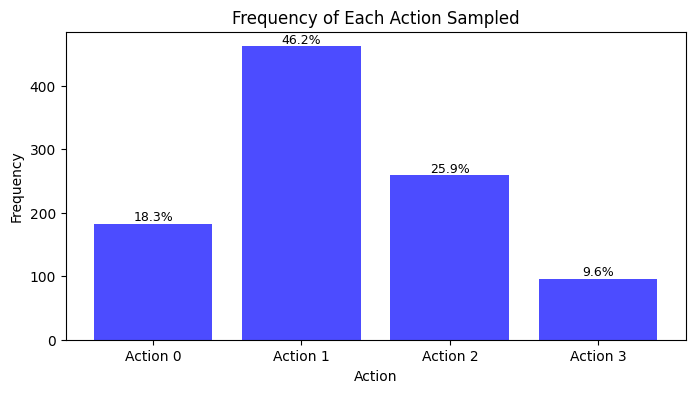

In [ ]:
# Action probabilities
a_probs = torch.tensor([0.2, 0.5, 0.3, 0.1], dtype=torch.float32)

# Categorical distribution with the given action probabilities
p_dist = Categorical(a_probs)

# Number of samples to draw
n_samples = 1000

# Record sampled actions
samples = []

for _ in range(n_samples):
    a = p_dist.sample()
    samples.append(a.item())

# Count occurrences of each action
action_counts = [samples.count(i) for i in range(len(a_probs))]

# Calculate percentages
percentages = [100 * count / n_samples for count in action_counts]

# Plot
plt.figure(figsize=(8, 4))
bars = plt.bar(range(len(a_probs)), action_counts, color='blue', alpha=0.7)
plt.xlabel('Action')
plt.ylabel('Frequency')
plt.title('Frequency of Each Action Sampled')

# Annotate bars with percentage values
for bar, percentage in zip(bars, percentages):
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, yval, f'{percentage:.1f}%', ha='center', va='bottom', fontsize=9)

plt.xticks(range(len(a_probs)), labels=[f"Action {i}" for i in range(len(a_probs))])
plt.show()

# Model: Vanilla Policy

In [ ]:
# Define model
class PolicyFCNet(nn.Module):
    def __init__(self, d_rate):
        super(PolicyFCNet, self).__init__()
        self.fc1 = nn.Linear(4, 128)
        self.dropout = nn.Dropout(d_rate)
        self.fc2 = nn.Linear(128, 2)

    def forward(self, x):
        x = F.relu(self.fc1(x))
        x = self.dropout(x)
        x = self.fc2(x)
        return F.softmax(x, dim=-1)

    def sample_action(self, a_probs, epsilon=0.1):
        n_actions = a_probs.shape[-1]
        if torch.rand(1).item() < epsilon:
            # ε-case: choose a random action uniformly.
            a = torch.randint(0, n_actions, (1,))
            prob = torch.clamp(a_probs[0, a.item()], min=1e-8, max=1e9)
            log_p = torch.log(prob).unsqueeze(0)
        else:
            # 1 - ε-case: sample from the policy distribution.
            p_dist = Categorical(a_probs)
            a = p_dist.sample()
            log_p = p_dist.log_prob(a)

        return a.item(), log_p

    def calculate_discounted_rewards(self, rewards, gamma, normalize=True):
        G_t = []
        G = 0
        for r in reversed(rewards):
            G = r + gamma * G
            G_t.insert(0, G)

        if normalize:
            G_t = torch.tensor(G_t, dtype=torch.float32)
            G_t = (G_t - G_t.mean()) / (G_t.std() + 1e-9)
        return G_t

    def compute_policy_loss(self, log_probs, discounted_rewards):
        losses = []
        for log_p, G in zip(log_probs, discounted_rewards):
            losses.append(-log_p * G)

        loss = torch.stack(losses).sum()
        return loss

# test model
d_rate = 0.2
model = PolicyFCNet(d_rate)

b_size = 16
in_dim = 4

x = torch.randn(b_size, in_dim)
output = model(x)
print(output.shape)

torch.Size([16, 2])


# Training

### Using Simple FC ( Vanilla Policy Gradient )

In [ ]:
# learning config
lr = 5e-3
d_rate = 0.5
epsilon = 0.1

# RL config
n_episodes = 1000
n_epochs = 200
n_epi_per_epoch = n_episodes // n_epochs
n_eval_episode = n_epi_per_epoch

print(f"RL config:")
print(f"👉 n_episodes       : {n_episodes}")
print(f"👉 n_epochs         : {n_epochs}")
print(f"👉 n_epi_per_epoch  : {n_epi_per_epoch}")

gamma = 0.99
threshold = 500

# model
agent = PolicyFCNet(d_rate)

# optimizer
optimizer = optim.Adam(agent.parameters(), lr=lr)

# set env with render_mode set to 'rgb_array' to allow proper rendering
env = gym.make("CartPole-v1", render_mode="rgb_array")

# init metrics
metrics = {
    "train_avg_rewards": [],
    "train_std_rewards": [],
    "train_avg_epi_lens": [],
    "train_acc": [],
    "eval_avg_rewards": [],
    "eval_std_rewards": [],
    "eval_avg_epi_len": [],
    "eval_acc": [],
}

RL config:
👉 n_episodes       : 1000
👉 n_epochs         : 200
👉 n_epi_per_epoch  : 5


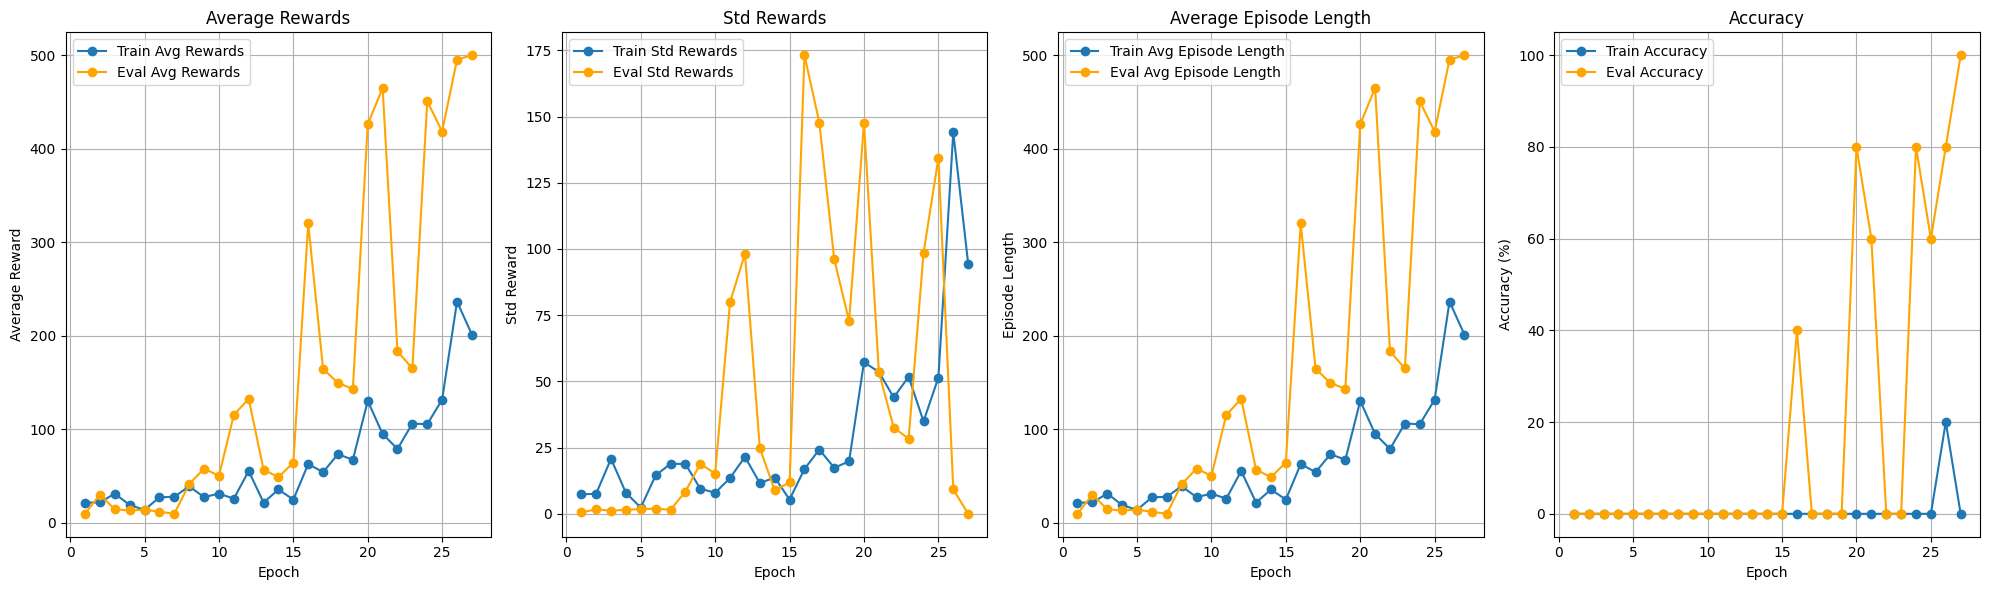

Episode: 0 | Total Reward: 179.0 | Episode Length: 179


In [ ]:
# Epoch-based training loop
for epoch in range(n_epochs):
    n_success = 0
    list_of_tot_rewards = []
    list_of_epi_lens = []

    for episode in range(n_epi_per_epoch):
        # init state
        obs, info = env.reset()

        # Buffers for storing log probabilities and rewards for the episode
        log_probs = []
        rewards = []

        done = False
        epi_len = 0
        while not done:
            # sample from our policy
            action_probs = agent(torch.from_numpy(obs).float().unsqueeze(0))

            # sample an action
            a_idx, log_p = agent.sample_action(action_probs, epsilon=epsilon)

            # Store the log probability of the action for later use in the loss
            log_probs.append(log_p)

            # Take the action in the environment
            obs, reward, done, truncated, info = env.step(a_idx)
            rewards.append(reward)

            # count epi length
            epi_len += 1

            # If the episode was truncated = episode is done
            if truncated:
                done = True

        # discounted rewards
        rewards_to_go = agent.calculate_discounted_rewards(rewards, gamma, normalize=True)

        # loss
        loss = agent.compute_policy_loss(log_probs, rewards_to_go)

        # optimize
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        # Print the total reward every 50 episodes
        if episode % 10 == 0:
            print(f"Episode: {episode} | Total Reward: {sum(rewards)} | Episode Length: {epi_len}")

        # Collect training metrics per episode
        n_success += 1 if epi_len >= 500 else 0
        list_of_tot_rewards.append(sum(rewards))
        list_of_epi_lens.append(epi_len)

    # Compute training metrics for this epoch
    train_acc = (n_success / n_epi_per_epoch) * 100
    train_avg_reward = np.mean(list_of_tot_rewards)
    train_std_reward = np.std(list_of_tot_rewards)
    train_avg_epi_len = np.mean(list_of_epi_lens)

    # Evaluate the current policy
    eval_metrics = evaluate_fc_policy(agent, env, n_eval_episode=n_eval_episode, threshold=threshold)

    # Save metrics (using the exact keys you provided)
    metrics["train_acc"].append(train_acc)
    metrics["train_avg_rewards"].append(train_avg_reward)
    metrics["train_std_rewards"].append(train_std_reward)
    metrics["train_avg_epi_lens"].append(train_avg_epi_len)
    metrics["eval_acc"].append(eval_metrics["eval_acc"])
    metrics["eval_avg_rewards"].append(eval_metrics["eval_avg_rewards"])
    metrics["eval_std_rewards"].append(eval_metrics["eval_std_rewards"])
    metrics["eval_avg_epi_len"].append(eval_metrics["eval_avg_epi_len"])

    # Update live plot with the new metrics
    live_plot(metrics)

# Save the model weights and close the environment
torch.save(agent.state_dict(), "policy_net_cartpole.pth")
env.close()
print("Training complete. Model weights saved as 'policy_net_cartpole.pth'.")